# PQ-IoMT: base paper vs. session-key variant

**What is compared.** In the base paper the sensor sends its signed reading to the edge server (QSES) in the clear. The variant first runs one ML-KEM-512 handshake per session to agree an AES-256 key with the QSES, then wraps every reading in AES-256-GCM under that key. The QSES → server hop is the same in both.

**The trade-off.** The paper (Sec. VIII-A) keeps the sensor to one operation, signing. The variant additionally makes the sensor do, once per session, an ML-KEM key generation, a decapsulation, one more signature and one more signature check, and one AES-GCM call per reading. This notebook measures what that costs (Part A), what it buys (Part B) and what the current implementation does not do (Part C).

## How the measurements are made

- **Same pipeline for both variants.** The sensor serialises its packet, the QSES parses bytes, the QSES serialises, the server parses bytes. (Passing Python objects in one variant and bytes in the other charges the parsing cost to only one of them.)
- **Interleaved A/B.** Base and variant run back to back inside one loop and swap who goes first every iteration, so clock-speed drift and background load hit both.
- **A/A control.** The server runs identical code in both variants. Its measured "difference" is therefore pure noise, and shows the smallest difference this setup can resolve.
- **Confidence intervals.** Differences are paired and reported with 95 % bootstrap intervals.
- **Added work timed directly.** ML-DSA signing has a heavy-tailed running time, so end-to-end differences of a few microseconds are hard to see. The extra statements the variant adds are therefore also timed on their own.
- **Host timings.** Everything runs through liboqs on this machine, not on a microcontroller. Treat ratios as indicative and absolute values as host-specific.

In [ ]:
import gc
import json
import os
import platform
import struct
import sys
import time
import tracemalloc
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import Markdown, display

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import oqs
from src.crypto.hashing import sha3_256
from src.crypto.kdf import derive_aes_key
from src.crypto.kem import KEMKeyPair, encapsulate
from src.crypto.signature import Signer, verify
from src.entities.client import ClientNode
from src.entities.qses import QSESNode
from src.entities.server import MedicalServerNode
from src.entities.secure_client import SecureClientNode
from src.entities.secure_qses import SecureQSESNode
from src.protocol.errors import ProtocolError
from src.protocol.messages import CLIENT_PACKET_SIZE, EDGE_PACKET_SIZE, IV_SIZE, ClientPacket
from src.protocol.secure_messages import (
    LINK_PACKET_SIZE, NONCE_SIZE, SESSION_ID_SIZE, SESSION_INFO, SensorLinkPacket,
    hello_bytes, reply_bytes,
)

TELEMETRY = b"Heart rate: 78"
N_ITER = 1000            # measured readings per variant
WARMUP = 20              # discarded
HS_N = 300               # handshakes timed
MICRO_N = 2000           # repetitions for single-operation timings
SAMPLE_INTERVAL_S = 30   # paper: vital signs every 30-60 s
SESSION_SIZES = [1, 5, 10, 50, 100, 500, 1000, 2000]
SAVE_FIGS = True
RNG = np.random.default_rng(12345)

FIG_DIR = ROOT / "comparison" / "figures"
RESULTS_PATH = ROOT / "comparison" / "comparison_results.json"
if SAVE_FIGS:
    FIG_DIR.mkdir(parents=True, exist_ok=True)

def _ver(name):
    fn = getattr(oqs, name, None)
    try:
        return fn() if fn else "unknown"
    except Exception:
        return "unknown"

ENV = {"python": sys.version.split()[0], "platform": platform.platform(),
       "machine": platform.machine(), "liboqs": _ver("oqs_version"),
       "liboqs-python": _ver("oqs_python_version")}
for k, v in ENV.items():
    print(f"{k:14} {v}")

# ---- plain figure style --------------------------------------------------
BASE_C = "#8c8c8c"
SEC_C = "#2b6cb0"
INK = "#222222"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#444444", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 10.5,
    "axes.labelsize": 10, "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 1.6, "xtick.color": INK, "ytick.color": INK,
    "text.color": INK, "axes.labelcolor": INK,
})

# ---- helpers -------------------------------------------------------------
@contextmanager
def no_gc():
    gc.collect()
    gc.disable()
    try:
        yield
    finally:
        gc.enable()

def summarize(x):
    a = np.asarray(x, dtype=float)
    return {"n": int(a.size), "mean": float(a.mean()), "median": float(np.median(a)),
            "stdev": float(a.std(ddof=1)) if a.size > 1 else 0.0,
            "p5": float(np.percentile(a, 5)), "p25": float(np.percentile(a, 25)),
            "p75": float(np.percentile(a, 75)), "p95": float(np.percentile(a, 95))}

def boot_ci(x, stat=np.mean, B=2000, alpha=0.05):
    """(point estimate, lo, hi) of stat(x) with a percentile bootstrap."""
    a = np.asarray(x, dtype=float)
    idx = RNG.integers(0, a.size, size=(B, a.size))
    s = stat(a[idx], axis=1)
    lo, hi = np.quantile(s, [alpha / 2, 1 - alpha / 2])
    return float(stat(a)), float(lo), float(hi)

def ab_loop(fn_a, in_a, fn_b, in_b, warmup=WARMUP):
    """Run fn_a(in_a[i]) and fn_b(in_b[i]) back to back, swapping who goes first every iteration.
    Returns (times_a_ms, times_b_ms, outputs_a, outputs_b); the first `warmup` times are dropped."""
    ta, tb, oa, ob = [], [], [], []
    with no_gc():
        for i in range(len(in_a)):
            for is_a in ((True, False) if i % 2 == 0 else (False, True)):
                fn, x = (fn_a, in_a[i]) if is_a else (fn_b, in_b[i])
                t0 = time.perf_counter()
                out = fn(x)
                dt = (time.perf_counter() - t0) * 1e3
                (oa if is_a else ob).append(out)
                (ta if is_a else tb).append(dt)
    return ta[warmup:], tb[warmup:], oa, ob

def micro(fn, n=MICRO_N, warmup=50):
    """Time one callable n times. Returns milliseconds."""
    with no_gc():
        for _ in range(warmup):
            fn()
        out = []
        for _ in range(n):
            t0 = time.perf_counter()
            fn()
            out.append((time.perf_counter() - t0) * 1e3)
    return out

def md_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "|" + "|".join("---" for _ in headers) + "|"]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    return "\n".join(lines)

def show_md(text):
    display(Markdown(text))

def save_fig(fig, name):
    if SAVE_FIGS:
        fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")

def duration(seconds):
    if seconds < 90:
        return f"{seconds:.0f} s"
    if seconds < 5400:
        return f"{seconds / 60:.0f} min"
    if seconds < 172800:
        return f"{seconds / 3600:.1f} h"
    return f"{seconds / 86400:.1f} d"

def ci_us(ci):
    """(point, lo, hi) in ms -> '+4.1 [-2.0, +10.2]' in microseconds."""
    p, lo, hi = (v * 1e3 for v in ci)
    return f"{p:+.1f} [{lo:+.1f}, {hi:+.1f}]"

R = {"env": ENV, "config": {"N_ITER": N_ITER, "WARMUP": WARMUP, "HS_N": HS_N,
                            "MICRO_N": MICRO_N, "SAMPLE_INTERVAL_S": SAMPLE_INTERVAL_S}}

python         3.13.5
platform       macOS-26.3.1-arm64-arm-64bit-Mach-O
machine        arm64
liboqs         0.16.0
liboqs-python  0.16.0.1


# Part A: what the variant costs

## A1. Time per reading, sensor / QSES / server

In [20]:
def build_base():
    server = MedicalServerNode(server_id=9)
    qses = QSESNode(server.public_key, max_age_ms=10 * 60 * 1000)
    client = ClientNode(client_id=1, server_id=9, session_id=3, qses_nonce=222)
    qses.register_client(1, client.public_key)
    server.trust_qses(qses.public_key)
    server.register_client(1, client.public_key, client.hmac_key, 222)
    return server, qses, client

def build_secure():
    server = MedicalServerNode(server_id=9)
    qses = SecureQSESNode(server.public_key, max_age_ms=10 * 60 * 1000)
    client = SecureClientNode(client_id=1, server_id=9, session_id=3, qses_nonce=222,
                              qses_public_key=qses.public_key)
    qses.register_client(1, client.public_key)
    server.trust_qses(qses.public_key)
    server.register_client(1, client.public_key, client.hmac_key, 222)
    return server, qses, client

def timed_handshake(qses, client):
    """One full handshake. Returns (sensor_ms, qses_ms, session_id)."""
    t0 = time.perf_counter()
    hello = client.begin_session()
    t1 = time.perf_counter()
    reply = qses.accept_session(*hello)
    t2 = time.perf_counter()
    client.complete_session(*reply)
    t3 = time.perf_counter()
    return ((t1 - t0) + (t3 - t2)) * 1e3, (t2 - t1) * 1e3, reply[1]

server_b, qses_b, client_b = build_base()
server_s, qses_s, client_s = build_secure()
timed_handshake(qses_s, client_s)   # opens the variant's session; its cost is measured separately in A3

total = WARMUP + N_ITER
readings = [TELEMETRY] * total

# stage 1: sensor builds the bytes that go on the radio link
sensor_base = lambda m: client_b.create_signed_reading(m).to_bytes()
sensor_secure = lambda m: client_s.create_encrypted_reading(m).to_bytes()
t_sen_b, t_sen_s, wire_b, wire_s = ab_loop(sensor_base, readings, sensor_secure, readings)

# stage 2: QSES takes those bytes and produces the bytes for the server
qses_base = lambda w: qses_b.process_and_forward(w).to_bytes()
qses_secure = lambda w: qses_s.receive_from_sensor(w).to_bytes()
t_qse_b, t_qse_s, edge_b, edge_s = ab_loop(qses_base, wire_b, qses_secure, wire_s)

# stage 3: server. Same code and same packet format in both variants -> A/A control
t_srv_b, t_srv_s, _, _ = ab_loop(server_b.receive_and_verify, edge_b,
                                 server_s.receive_and_verify, edge_s)
assert len(server_b.database) == len(server_s.database) == total, "server rejected something"
assert len(wire_b[0]) == CLIENT_PACKET_SIZE and len(wire_s[0]) == LINK_PACKET_SIZE

stages = {}
for name, (a, b) in {"Sensor": (t_sen_b, t_sen_s), "QSES": (t_qse_b, t_qse_s),
                     "Server (A/A control)": (t_srv_b, t_srv_s)}.items():
    a, b = np.array(a), np.array(b)
    d = b - a
    stages[name] = {"base": summarize(a), "secure": summarize(b),
                    "d_mean": boot_ci(d, np.mean), "d_median": boot_ci(d, np.median)}

rows = []
for name, s in stages.items():
    rows.append([name, f"{s['base']['median'] * 1e3:.1f}", f"{s['secure']['median'] * 1e3:.1f}",
                 f"{s['base']['mean'] * 1e3:.1f}", f"{s['secure']['mean'] * 1e3:.1f}",
                 ci_us(s["d_mean"]), ci_us(s["d_median"])])
show_md(f"Time per reading over {N_ITER} readings per variant (microseconds). "
        "Differences are variant minus base, with 95 % bootstrap intervals.\n\n" +
        md_table(["stage", "base median", "variant median", "base mean", "variant mean",
                  "difference of means", "difference of medians"], rows))

aa = stages["Server (A/A control)"]["d_mean"]
noise_us = (aa[2] - aa[1]) / 2 * 1e3
if aa[1] <= 0 <= aa[2]:
    show_md(f"A/A control: the identical server code shows {ci_us(aa)} µs, which includes zero, as it should. "
            f"Differences much smaller than about {noise_us:.1f} µs cannot be resolved by this end-to-end comparison.")
else:
    show_md(f"**Warning.** The A/A control shows {ci_us(aa)} µs and excludes zero, so this run has a systematic offset "
            "(background load, frequency scaling). Re-run on an idle machine before trusting small differences.")

R["ab"] = {k: v for k, v in stages.items()}
R["samples_ms"] = {"sensor_base": np.round(t_sen_b, 6).tolist(), "sensor_variant": np.round(t_sen_s, 6).tolist(),
                   "qses_base": np.round(t_qse_b, 6).tolist(), "qses_variant": np.round(t_qse_s, 6).tolist(),
                   "server_base": np.round(t_srv_b, 6).tolist(), "server_variant": np.round(t_srv_s, 6).tolist()}

Time per reading over 1000 readings per variant (microseconds). Differences are variant minus base, with 95 % bootstrap intervals.

| stage | base median | variant median | base mean | variant mean | difference of means | difference of medians |
|---|---|---|---|---|---|---|
| Sensor | 68.8 | 76.4 | 82.1 | 87.8 | +5.6 [+2.2, +9.0] | +5.6 [+4.8, +7.3] |
| QSES | 137.3 | 140.4 | 148.3 | 154.1 | +5.8 [+2.2, +9.5] | +4.5 [+2.7, +5.8] |
| Server (A/A control) | 106.5 | 106.5 | 154.9 | 156.6 | +1.7 [-45.4, +47.9] | +0.1 [-0.0, +0.2] |

A/A control: the identical server code shows +1.7 [-45.4, +47.9] µs, which includes zero, as it should. Differences much smaller than about 46.6 µs cannot be resolved by this end-to-end comparison.

## A2. The added work, timed directly

Signing dominates the sensor and the QSES, and its running time varies from call to call. That variation sits on top of the few microseconds the variant adds, so the end-to-end comparison above has wide intervals. Here we time only the statements the variant adds, nothing else.

- **Sensor:** pack the session id, AES-GCM encrypt the 2,584-byte packet, build and serialise the link packet.
- **QSES:** parse the link packet, look up the session key, AES-GCM decrypt.

In [21]:
# Read from the live objects only so that exactly the added statements are timed.
cipher_s = client_s._link_cipher
sid_s = client_s._link_session_id
inner = client_s.create_signed_reading(TELEMETRY).to_bytes()     # the 2,584-byte ClientPacket

def added_at_sensor():
    header = struct.pack(">I", sid_s)
    iv, ct, tag = cipher_s.encrypt_detached(inner, header)
    return SensorLinkPacket(sid_s, iv, ct, tag).to_bytes()

wire_probe = wire_s[-1]
def added_at_qses():
    lp = SensorLinkPacket.from_bytes(wire_probe)
    return qses_s.sessions[lp.session_id].decrypt_detached(lp.iv, lp.ciphertext, lp.tag, lp.header())

direct = {}
for name, fn in (("Sensor", added_at_sensor), ("QSES", added_at_qses)):
    s = micro(fn)
    direct[name] = {"stats": summarize(s), "mean_ci": boot_ci(s, np.mean)}
direct_est = {k: v["stats"]["mean"] for k, v in direct.items()}

rows = []
for name in ("Sensor", "QSES"):
    d = direct[name]
    base_mean = stages[name]["base"]["mean"]
    rows.append([name, f"{d['stats']['mean'] * 1e3:.2f}",
                 f"[{d['mean_ci'][1] * 1e3:.2f}, {d['mean_ci'][2] * 1e3:.2f}]",
                 f"{base_mean * 1e3:.1f}", f"{100 * d['stats']['mean'] / base_mean:.1f} %"])
show_md("Added work per reading, measured on its own (microseconds)\n\n" +
        md_table(["where", "added work, mean", "95 % interval", "base time per reading, mean", "added / base"], rows))
R["direct"] = direct

Added work per reading, measured on its own (microseconds)

| where | added work, mean | 95 % interval | base time per reading, mean | added / base |
|---|---|---|---|---|
| Sensor | 6.37 | [5.94, 6.84] | 82.1 | 7.7 % |
| QSES | 3.61 | [3.54, 3.69] | 148.3 | 2.4 % |

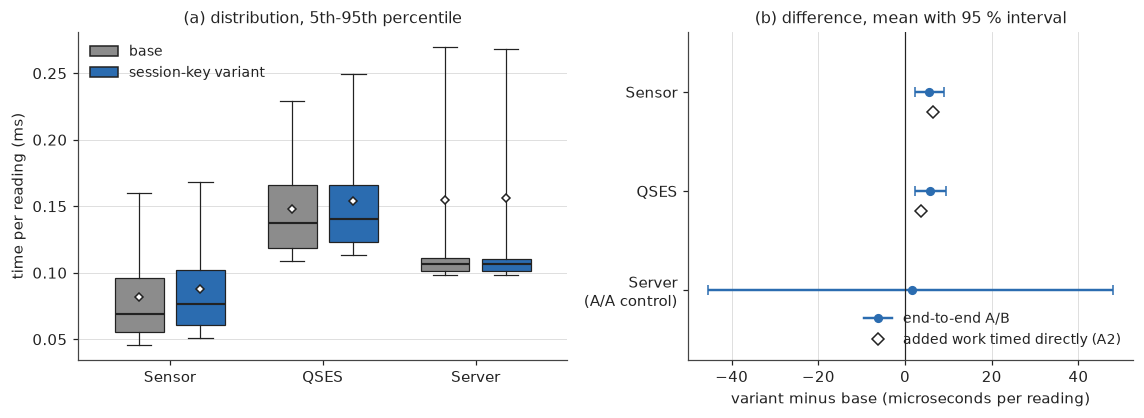

In [22]:
names = ["Sensor", "QSES", "Server"]
data_b = [t_sen_b, t_qse_b, t_srv_b]
data_s = [t_sen_s, t_qse_s, t_srv_s]

fig, (axa, axb) = plt.subplots(1, 2, figsize=(10.5, 3.9), gridspec_kw={"width_ratios": [1.1, 1]})

for k in range(3):
    for off, d, col in ((-0.2, data_b[k], BASE_C), (0.2, data_s[k], SEC_C)):
        axa.boxplot(d, positions=[k + off], widths=0.32, whis=(5, 95), showfliers=False,
                    patch_artist=True, showmeans=True,
                    medianprops=dict(color=INK, lw=1.4),
                    meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor=INK, markersize=4),
                    boxprops=dict(facecolor=col, edgecolor=INK, lw=0.8),
                    whiskerprops=dict(color=INK, lw=0.8), capprops=dict(color=INK, lw=0.8))
axa.set_xticks(range(3))
axa.set_xticklabels(names)
axa.set_xlim(-0.6, 2.6)
axa.set_ylabel("time per reading (ms)")
axa.set_title("(a) distribution, 5th-95th percentile")
axa.grid(axis="x", visible=False)
axa.legend(handles=[Patch(facecolor=BASE_C, edgecolor=INK, label="base"),
                    Patch(facecolor=SEC_C, edgecolor=INK, label="session-key variant")],
           loc="upper left")

ylabels, ypos = ["Sensor", "QSES", "Server\n(A/A control)"], [2, 1, 0]
for y, key in zip(ypos, ["Sensor", "QSES", "Server (A/A control)"]):
    m, lo, hi = (v * 1e3 for v in stages[key]["d_mean"])
    axb.errorbar(m, y, xerr=[[m - lo], [hi - m]], fmt="o", color=SEC_C, capsize=3, ms=5)
    if key in direct_est:
        axb.plot(direct_est[key] * 1e3, y - 0.2, "D", color=INK, mfc="white", ms=6)
axb.axvline(0, color=INK, lw=0.8)
axb.set_yticks(ypos)
axb.set_yticklabels(ylabels)
axb.set_ylim(-0.7, 2.6)
axb.set_xlabel("variant minus base (microseconds per reading)")
axb.set_title("(b) difference, mean with 95 % interval")
axb.grid(axis="y", visible=False)
axb.legend(handles=[Line2D([], [], marker="o", color=SEC_C, label="end-to-end A/B", ms=5),
                    Line2D([], [], marker="D", color=INK, mfc="white", ls="", label="added work timed directly (A2)", ms=6)],
           loc="lower right")

plt.tight_layout()
save_fig(fig, "fig1_latency.png")
plt.show()

**Figure 1.** (a) Time per reading at each stage. Box = middle half, line = median, diamond = mean, whiskers = 5th to 95th percentile. ML-DSA signing has a long upper tail, which is why the sensor and QSES boxes are wide. (b) Variant minus base. The bar is the 95 % interval of the end-to-end difference; the open diamond is the added work timed on its own (A2). The server row runs identical code in both variants, so it shows the noise level.

## A3. The one-off handshake, split by who pays

The paper's argument is about the sensor, so what matters is how much of the handshake lands on the sensor and how much on the QSES. The first table times the real handshake code. The second times each operation on its own; the parts should add up to roughly the whole.

In [23]:
hs_server, hs_qses, hs_client = build_secure()
hs_sensor_ms, hs_qses_ms = [], []
with no_gc():
    for i in range(HS_N + WARMUP):
        s_ms, q_ms, _ = timed_handshake(hs_qses, hs_client)
        if i >= WARMUP:
            hs_sensor_ms.append(s_ms)
            hs_qses_ms.append(q_ms)
hs_sensor_ms, hs_qses_ms = np.array(hs_sensor_ms), np.array(hs_qses_ms)

# --- each operation on its own, with realistic inputs ----
dev_signer, qses_signer = Signer(), Signer()
kem_pair = KEMKeyPair()
n_i, n_q = os.urandom(NONCE_SIZE), os.urandom(NONCE_SIZE)
hello_msg = hello_bytes(1, n_i, kem_pair.public_key)
sig_hello = dev_signer.sign(sha3_256(hello_msg))
ct_probe, ss_probe = encapsulate(kem_pair.public_key)
reply_msg = reply_bytes(1, n_i, n_q, 1234, ct_probe)
sig_reply = qses_signer.sign(sha3_256(reply_msg))
salt_probe = n_i + n_q

def _keygen():
    k = KEMKeyPair()
    k.close()

sensor_ops = [
    ("ML-KEM keygen", _keygen),
    ("ML-DSA sign (hello)", lambda: dev_signer.sign(sha3_256(hello_msg))),
    ("ML-DSA verify (reply)", lambda: verify(sha3_256(reply_msg), sig_reply, qses_signer.public_key)),
    ("ML-KEM decaps", lambda: kem_pair.decapsulate(ct_probe)),
    ("HKDF", lambda: derive_aes_key(ss_probe, salt_probe, info=SESSION_INFO)),
]
qses_ops = [
    ("ML-DSA verify (hello)", lambda: verify(sha3_256(hello_msg), sig_hello, dev_signer.public_key)),
    ("ML-KEM encaps", lambda: encapsulate(kem_pair.public_key)),
    ("HKDF", lambda: derive_aes_key(ss_probe, salt_probe, info=SESSION_INFO)),
    ("ML-DSA sign (reply)", lambda: qses_signer.sign(sha3_256(reply_msg))),
]
op_cost = {"Sensor": [(n, float(np.mean(micro(f, n=500)))) for n, f in sensor_ops],
           "QSES": [(n, float(np.mean(micro(f, n=500)))) for n, f in qses_ops]}

whole = {"Sensor": hs_sensor_ms, "QSES": hs_qses_ms}
rows = []
for who in ("Sensor", "QSES"):
    parts = sum(c for _, c in op_cost[who])
    rows.append([who, f"{whole[who].mean() * 1e3:.1f}", f"{np.median(whole[who]) * 1e3:.1f}",
                 f"{np.percentile(whole[who], 95) * 1e3:.1f}", f"{parts * 1e3:.1f}"])
rows.append(["both", f"{(hs_sensor_ms + hs_qses_ms).mean() * 1e3:.1f}",
             f"{np.median(hs_sensor_ms + hs_qses_ms) * 1e3:.1f}",
             f"{np.percentile(hs_sensor_ms + hs_qses_ms, 95) * 1e3:.1f}", ""])
show_md(f"Handshake time over {HS_N} handshakes (microseconds)\n\n" +
        md_table(["party", "whole, mean", "whole, median", "whole, p95", "sum of single operations, mean"], rows))

rows = []
for who in ("Sensor", "QSES"):
    for n, c in op_cost[who]:
        rows.append([who, n, f"{c * 1e3:.1f}"])
show_md("Single operations (microseconds, mean)\n\n" + md_table(["party", "operation", "time"], rows))

sensor_hs_in_readings = hs_sensor_ms.mean() / stages["Sensor"]["base"]["mean"]
R["handshake"] = {"sensor_ms": summarize(hs_sensor_ms), "qses_ms": summarize(hs_qses_ms),
                  "ops_ms": op_cost, "sensor_in_base_readings": float(sensor_hs_in_readings)}
print(f"One handshake costs the sensor as much time as {sensor_hs_in_readings:.1f} base readings (mean vs mean).")

Handshake time over 300 handshakes (microseconds)

| party | whole, mean | whole, median | whole, p95 | sum of single operations, mean |
|---|---|---|---|---|
| Sensor | 184.5 | 154.0 | 403.6 | 151.2 |
| QSES | 167.8 | 142.1 | 300.0 | 131.1 |
| both | 352.3 | 303.6 | 622.8 |  |

Single operations (microseconds, mean)

| party | operation | time |
|---|---|---|
| Sensor | ML-KEM keygen | 13.3 |
| Sensor | ML-DSA sign (hello) | 83.9 |
| Sensor | ML-DSA verify (reply) | 38.8 |
| Sensor | ML-KEM decaps | 12.0 |
| Sensor | HKDF | 3.1 |
| QSES | ML-DSA verify (hello) | 35.5 |
| QSES | ML-KEM encaps | 14.4 |
| QSES | HKDF | 3.1 |
| QSES | ML-DSA sign (reply) | 78.1 |

One handshake costs the sensor as much time as 2.2 base readings (mean vs mean).


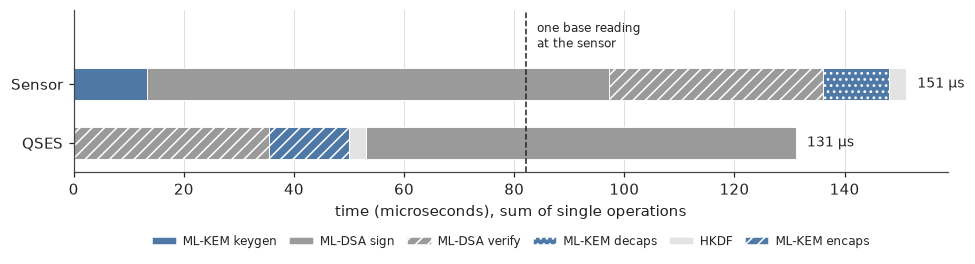

In [24]:
STYLE = {"ML-KEM keygen": ("#4e79a7", ""), "ML-KEM encaps": ("#4e79a7", "///"),
         "ML-KEM decaps": ("#4e79a7", "..."), "ML-DSA sign": ("#9a9a9a", ""),
         "ML-DSA verify": ("#9a9a9a", "///"), "HKDF": ("#e3e3e3", "")}
def style_for(label):
    for key, st in STYLE.items():
        if label.startswith(key):
            return key, st
    raise KeyError(label)

fig, ax = plt.subplots(figsize=(9, 2.7))
for y, who in ((1, "Sensor"), (0, "QSES")):
    left = 0.0
    for label, ms in op_cost[who]:
        _, (col, hatch) = style_for(label)
        w = ms * 1e3
        ax.barh(y, w, left=left, color=col, hatch=hatch, edgecolor="white", height=0.55, linewidth=0.6)
        left += w
    ax.text(left + 2, y, f"{left:.0f} µs", va="center", fontsize=9)

ref = stages["Sensor"]["base"]["mean"] * 1e3
ax.axvline(ref, color=INK, ls="--", lw=1)
ax.text(ref + 2, 1.55, "one base reading\nat the sensor", fontsize=8, va="bottom")
ax.set_yticks([1, 0])
ax.set_yticklabels(["Sensor", "QSES"])
ax.set_ylim(-0.5, 2.25)
ax.set_xlabel("time (microseconds), sum of single operations")
ax.grid(axis="y", visible=False)
seen = {}
for who in op_cost:
    for label, _ in op_cost[who]:
        key, (col, hatch) = style_for(label)
        seen[key] = Patch(facecolor=col, hatch=hatch, edgecolor="white", label=key)
ax.legend(handles=list(seen.values()), ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.32),
          fontsize=8, columnspacing=1.0, handletextpad=0.5)
plt.tight_layout()
save_fig(fig, "fig2_handshake.png")
plt.show()

**Figure 2.** What one handshake costs each party, broken down by operation. Blue is ML-KEM, grey is ML-DSA (plain = sign, hatched = verify), light grey is HKDF. The dashed line marks the sensor's cost of one ordinary reading in the base protocol, for scale.

## A4. Bytes on the radio link and what the sensor has to hold

Sizes below come from the running code and from liboqs, not from the paper. The handshake messages exist in the code only as Python tuples (there is no serialiser), so their byte counts assume 4-byte integer fields.

In [25]:
def oqs_sizes():
    try:
        with oqs.KeyEncapsulation("ML-KEM-512") as k:
            kd = k.details
        with oqs.Signature("ML-DSA-44") as s:
            sd = s.details
        return dict(kem_pk=kd["length_public_key"], kem_sk=kd["length_secret_key"],
                    kem_ct=kd["length_ciphertext"], kem_ss=kd["length_shared_secret"],
                    sig_pk=sd["length_public_key"], sig_sk=sd["length_secret_key"],
                    sig=sd["length_signature"])
    except Exception as e:
        print("could not read sizes from liboqs, using the standard FIPS 203/204 values:", e)
        return dict(kem_pk=800, kem_sk=1632, kem_ct=768, kem_ss=32, sig_pk=1312, sig_sk=2560, sig=2420)

SZ = oqs_sizes()
HMAC_KEY = 32

# handshake messages, from the real objects used above
hello_len = SESSION_ID_SIZE + len(n_i) + len(kem_pair.public_key) + len(sig_hello)     # id, n_i, pk_kem, sigma_D
reply_len = len(n_q) + SESSION_ID_SIZE + len(ct_probe) + len(sig_reply)                # n_q, session id, ct, sigma_Q
hs_bytes = hello_len + reply_len
extra_per_reading = LINK_PACKET_SIZE - CLIENT_PACKET_SIZE

rows = [
    ["per reading, sensor -> QSES", f"{CLIENT_PACKET_SIZE:,}", f"{LINK_PACKET_SIZE:,}", f"+{extra_per_reading}"],
    ["per reading, QSES -> server", f"{EDGE_PACKET_SIZE:,}", f"{EDGE_PACKET_SIZE:,}", "0"],
    ["per session, sensor sends (hello)", "0", f"{hello_len:,}", f"+{hello_len:,}"],
    ["per session, sensor receives (reply)", "0", f"{reply_len:,}", f"+{reply_len:,}"],
]
show_md("Bytes on the wire\n\n" + md_table(["", "base", "variant", "difference"], rows))

transient = SZ["kem_sk"] + SZ["kem_pk"] + SZ["kem_ct"] + SZ["kem_ss"] + 2 * NONCE_SIZE
rows = [
    ["ML-DSA secret key", f"{SZ['sig_sk']:,}", f"{SZ['sig_sk']:,}", "kept for the device lifetime"],
    ["HMAC key", f"{HMAC_KEY}", f"{HMAC_KEY}", "kept"],
    ["QSES public key", "0", f"{SZ['sig_pk']:,}", "kept; needed to check the handshake reply"],
    ["ML-KEM secret key, public key, ciphertext, shared secret, two nonces", "0", f"{transient:,}",
     "only during the handshake, then freed"],
    ["session key and session id", "0", f"{32 + SESSION_ID_SIZE}", "kept while the session lasts"],
]
show_md("Key material and buffers the sensor holds (bytes). Protocol-level sizes only: working memory of the "
        "ML-KEM and ML-DSA implementations is not included.\n\n" +
        md_table(["item", "base", "variant", "lifetime"], rows))

R["bytes"] = {"hello": hello_len, "reply": reply_len, "handshake_total": hs_bytes,
              "link_base": CLIENT_PACKET_SIZE, "link_variant": LINK_PACKET_SIZE,
              "hop2": EDGE_PACKET_SIZE, "sensor_transient": transient, "oqs_sizes": SZ}

Bytes on the wire

|  | base | variant | difference |
|---|---|---|---|
| per reading, sensor -> QSES | 2,584 | 2,616 | +32 |
| per reading, QSES -> server | 5,832 | 5,832 | 0 |
| per session, sensor sends (hello) | 0 | 3,240 | +3,240 |
| per session, sensor receives (reply) | 0 | 3,208 | +3,208 |

Key material and buffers the sensor holds (bytes). Protocol-level sizes only: working memory of the ML-KEM and ML-DSA implementations is not included.

| item | base | variant | lifetime |
|---|---|---|---|
| ML-DSA secret key | 2,560 | 2,560 | kept for the device lifetime |
| HMAC key | 32 | 32 | kept |
| QSES public key | 0 | 1,312 | kept; needed to check the handshake reply |
| ML-KEM secret key, public key, ciphertext, shared secret, two nonces | 0 | 3,264 | only during the handshake, then freed |
| session key and session id | 0 | 36 | kept while the session lasts |

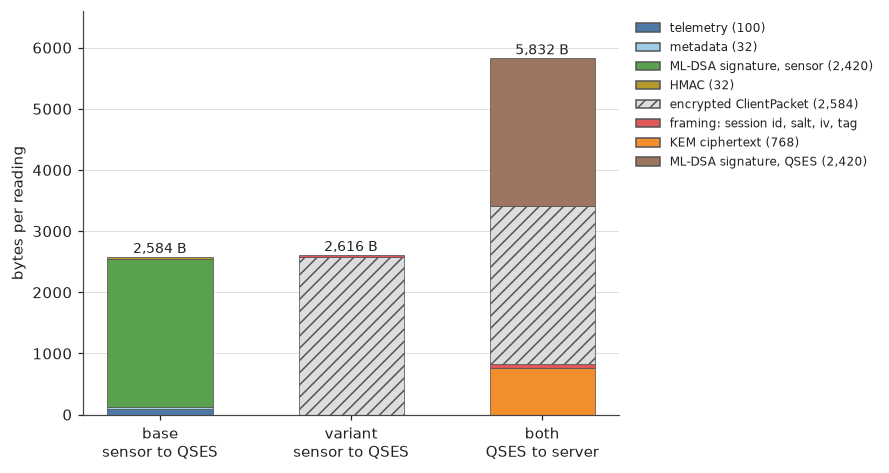

In [26]:
fig, ax = plt.subplots(figsize=(8.2, 4.4))

PAL = {"telemetry (100)": "#4e79a7", "metadata (32)": "#a0cbe8", "ML-DSA signature, sensor (2,420)": "#59a14f",
       "HMAC (32)": "#b6992d", "encrypted ClientPacket (2,584)": "#dddddd",
       "framing: session id, salt, iv, tag": "#e15759", "KEM ciphertext (768)": "#f28e2b",
       "ML-DSA signature, QSES (2,420)": "#9c755f"}

bars = [
    ("base\nsensor to QSES", [("telemetry (100)", 100), ("metadata (32)", 32),
                              ("ML-DSA signature, sensor (2,420)", 2420), ("HMAC (32)", 32)]),
    ("variant\nsensor to QSES", [("encrypted ClientPacket (2,584)", CLIENT_PACKET_SIZE),
                                 ("framing: session id, salt, iv, tag", extra_per_reading)]),
    ("both\nQSES to server", [("KEM ciphertext (768)", 768), ("framing: session id, salt, iv, tag", 60),
                              ("encrypted ClientPacket (2,584)", CLIENT_PACKET_SIZE),
                              ("ML-DSA signature, QSES (2,420)", 2420)]),
]
for x, (label, parts) in enumerate(bars):
    bottom = 0
    for name, size in parts:
        hatch = "///" if name.startswith("encrypted") else ""
        ax.bar(x, size, 0.55, bottom=bottom, color=PAL[name], hatch=hatch, edgecolor="#555555", linewidth=0.5)
        bottom += size
    ax.text(x, bottom + 60, f"{bottom:,} B", ha="center", fontsize=9)
ax.set_xticks(range(3))
ax.set_xticklabels([b[0] for b in bars])
ax.set_ylabel("bytes per reading")
ax.set_ylim(0, 6600)
ax.grid(axis="x", visible=False)
handles = [Patch(facecolor=c, hatch="///" if n.startswith("encrypted") else "", edgecolor="#555555", label=n)
           for n, c in PAL.items()]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8)
plt.tight_layout()
save_fig(fig, "fig3_packets.png")
plt.show()

**Figure 3.** Contents of each packet. The variant wraps the same 2,584-byte ClientPacket (hatched = encrypted) in a 32-byte frame: session id (4), IV (12) and GCM tag (16). The 60 bytes of framing in the QSES to server packet are the salt (32), IV (12) and GCM tag (16). The QSES → server packet is identical in both variants.

## A5. How the one-off cost spreads over a session

If a session carries `n` readings, each reading carries `1/n` of the handshake plus the per-reading extra. A shorter session means a key that protects less data, but a larger share of handshake cost per reading. The top axis labels convert `n` to time at one reading every `SAMPLE_INTERVAL_S` seconds.

(Random 96-bit AES-GCM IVs would allow about 2^32 messages under one key, NIST SP 800-38D, so session length here is a choice about exposure, not a cipher limit.)

In [27]:
add_sensor_ms = direct["Sensor"]["stats"]["mean"]
add_qses_ms = direct["QSES"]["stats"]["mean"]
hs_s_ms, hs_q_ms = float(hs_sensor_ms.mean()), float(hs_qses_ms.mean())

def extra_us(n):
    return (hs_s_ms / n + add_sensor_ms) * 1e3, (hs_q_ms / n + add_qses_ms) * 1e3

def extra_bytes(n):
    return hs_bytes / n + extra_per_reading

rows = []
for n in SESSION_SIZES:
    s_us, q_us = extra_us(n)
    rows.append([f"{n:,}", duration(n * SAMPLE_INTERVAL_S), f"{s_us:.1f}", f"{q_us:.1f}",
                 f"{extra_bytes(n):,.0f}", f"{100 * extra_bytes(n) / CLIENT_PACKET_SIZE:.1f} %"])
show_md("Extra cost per reading, handshake included\n\n" +
        md_table(["readings per session", f"duration at 1 per {SAMPLE_INTERVAL_S} s", "sensor extra time (µs)",
                  "QSES extra time (µs)", "extra bytes on sensor link", "as % of base packet"], rows))

n_half_sensor = hs_s_ms / add_sensor_ms
n_half_qses = hs_q_ms / add_qses_ms
n_half_bytes = hs_bytes / extra_per_reading
print("Handshake is more than half of the extra cost until the session reaches about:")
print(f"  sensor time : {n_half_sensor:7.0f} readings ({duration(n_half_sensor * SAMPLE_INTERVAL_S)})")
print(f"  QSES time   : {n_half_qses:7.0f} readings ({duration(n_half_qses * SAMPLE_INTERVAL_S)})")
print(f"  bytes       : {n_half_bytes:7.0f} readings ({duration(n_half_bytes * SAMPLE_INTERVAL_S)})")
print("Beyond that point the per-reading extra is the larger part. The variant never 'pays back':")
print("it always costs more than base; the question is only how the cost is split.")
R["amortization"] = {"n_half_sensor": n_half_sensor, "n_half_qses": n_half_qses, "n_half_bytes": n_half_bytes}

Extra cost per reading, handshake included

| readings per session | duration at 1 per 30 s | sensor extra time (µs) | QSES extra time (µs) | extra bytes on sensor link | as % of base packet |
|---|---|---|---|---|---|
| 1 | 30 s | 190.9 | 171.4 | 6,480 | 250.8 % |
| 5 | 2 min | 43.3 | 37.2 | 1,322 | 51.1 % |
| 10 | 5 min | 24.8 | 20.4 | 677 | 26.2 % |
| 50 | 25 min | 10.1 | 7.0 | 161 | 6.2 % |
| 100 | 50 min | 8.2 | 5.3 | 96 | 3.7 % |
| 500 | 4.2 h | 6.7 | 3.9 | 45 | 1.7 % |
| 1,000 | 8.3 h | 6.5 | 3.8 | 38 | 1.5 % |
| 2,000 | 16.7 h | 6.5 | 3.7 | 35 | 1.4 % |

Handshake is more than half of the extra cost until the session reaches about:
  sensor time :      29 readings (14 min)
  QSES time   :      47 readings (23 min)
  bytes       :     202 readings (1.7 h)
Beyond that point the per-reading extra is the larger part. The variant never 'pays back':
it always costs more than base; the question is only how the cost is split.


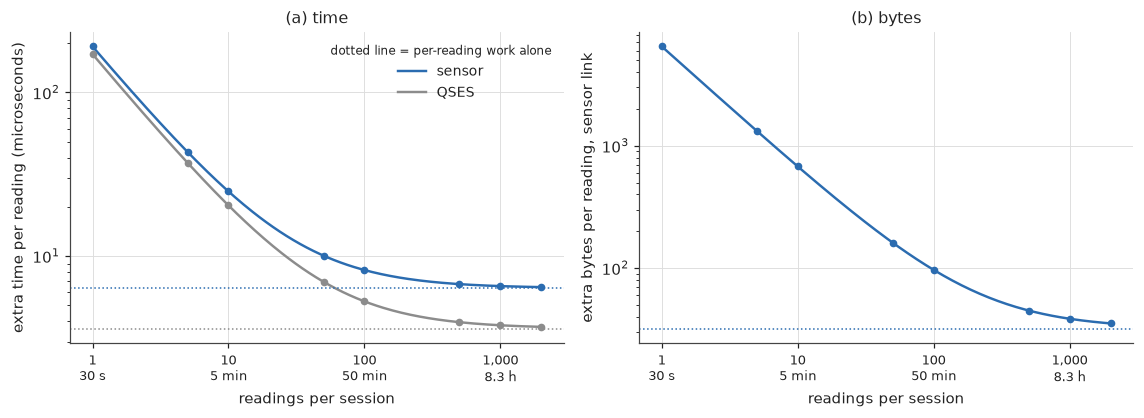

In [28]:
ns = np.logspace(0, np.log10(max(SESSION_SIZES)), 200)
TICKS = [n for n in (1, 10, 100, 1000) if n <= max(SESSION_SIZES)]
xt_labels = [f"{n:,}\n{duration(n * SAMPLE_INTERVAL_S)}" for n in TICKS]

fig, (axa, axb) = plt.subplots(1, 2, figsize=(10.5, 3.9))

sens = np.array([extra_us(n)[0] for n in ns])
qs = np.array([extra_us(n)[1] for n in ns])
axa.plot(ns, sens, color=SEC_C, label="sensor")
axa.plot(ns, qs, color=BASE_C, label="QSES")
axa.axhline(add_sensor_ms * 1e3, color=SEC_C, ls=":", lw=1)
axa.axhline(add_qses_ms * 1e3, color=BASE_C, ls=":", lw=1)
axa.plot(SESSION_SIZES, [extra_us(n)[0] for n in SESSION_SIZES], "o", color=SEC_C, ms=4)
axa.plot(SESSION_SIZES, [extra_us(n)[1] for n in SESSION_SIZES], "o", color=BASE_C, ms=4)
axa.set_xscale("log"); axa.set_yscale("log")
axa.set_xticks(TICKS); axa.set_xticklabels(xt_labels, fontsize=8.5)
axa.tick_params(axis="x", which="minor", bottom=False)
axa.set_xlabel("readings per session")
axa.set_ylabel("extra time per reading (microseconds)")
axa.set_title("(a) time")
axa.legend(title="dotted line = per-reading work alone", title_fontsize=8, loc="upper right")

axb.plot(ns, [extra_bytes(n) for n in ns], color=SEC_C)
axb.axhline(extra_per_reading, color=SEC_C, ls=":", lw=1)
axb.plot(SESSION_SIZES, [extra_bytes(n) for n in SESSION_SIZES], "o", color=SEC_C, ms=4)
axb.set_xscale("log"); axb.set_yscale("log")
axb.set_xticks(TICKS); axb.set_xticklabels(xt_labels, fontsize=8.5)
axb.tick_params(axis="x", which="minor", bottom=False)
axb.set_xlabel("readings per session")
axb.set_ylabel("extra bytes per reading, sensor link")
axb.set_title("(b) bytes")

plt.tight_layout()
save_fig(fig, "fig4_amortization.png")
plt.show()

**Figure 4.** Extra cost per reading as the session gets longer, handshake included. Dotted lines are the per-reading extra on its own, which the curves approach. Both axes are logarithmic; markers are at the session sizes in the table above. Tick labels give the number of readings and the session length at one reading per `SAMPLE_INTERVAL_S` seconds.

## A6. State kept at the QSES

The base QSES stores one public key and one sequence number per sensor. The variant also stores a session key per session. We open many sessions on one QSES and measure what Python keeps allocated (the Python-level objects only, not liboqs or OpenSSL memory).

In [29]:
def qses_session_state(n_sessions=300):
    sv = MedicalServerNode(server_id=9)
    q = SecureQSESNode(sv.public_key)
    c = SecureClientNode(client_id=1, server_id=9, session_id=3, qses_nonce=222, qses_public_key=q.public_key)
    q.register_client(1, c.public_key)
    gc.collect()
    tracemalloc.start()
    before = tracemalloc.get_traced_memory()[0]
    for _ in range(n_sessions):
        reply = q.accept_session(*c.begin_session())
        c.complete_session(*reply)
    gc.collect()
    after = tracemalloc.get_traced_memory()[0]
    tracemalloc.stop()
    return (after - before) / n_sessions, len(q.sessions), len(q._seen_n_i)

per_session_bytes, kept_sessions, kept_nonces = qses_session_state()
show_md(md_table(["after 300 handshakes on one QSES", "value"], [
    ["session keys still held", f"{kept_sessions}"],
    ["handshake nonces still remembered", f"{kept_nonces}"],
    ["Python memory retained per session", f"about {per_session_bytes:,.0f} bytes"],
]))
R["qses_state"] = {"bytes_per_session": per_session_bytes, "sessions_kept": kept_sessions}

| after 300 handshakes on one QSES | value |
|---|---|
| session keys still held | 300 |
| handshake nonces still remembered | 300 |
| Python memory retained per session | about 299 bytes |

# Part B: what the extra cost buys

## B1. What a passive listener on the sensor link can read

The listener is assumed to know the packet formats (nothing here relies on secrecy of the format). We capture 200 packets from each variant and let the listener do the best it can: slice out the 2,584-byte body and read it as a ClientPacket.

In [30]:
N_CAP = 200
cap_b, cap_s = wire_b[WARMUP:WARMUP + N_CAP], wire_s[WARMUP:WARMUP + N_CAP]
BODY_OFFSET = {"base": 0, "variant": SESSION_ID_SIZE + IV_SIZE}      # where the 2,584-byte body starts

def observer_view(wires, offset):
    readable, ids, seqs, first = 0, set(), [], None
    for w in wires:
        pkt = ClientPacket.from_bytes(w[offset:offset + CLIENT_PACKET_SIZE])
        if pkt.message.rstrip(b"\x00") == TELEMETRY:
            readable += 1
        m = pkt.metadata
        ids.add(m.client_id)
        seqs.append(m.seq)
        first = first or m
    consecutive = sum(b == a + 1 for a, b in zip(seqs, seqs[1:]))
    return {"readable": readable, "distinct_ids": len(ids), "consecutive": consecutive, "first": first}

ob, os_ = observer_view(cap_b, BODY_OFFSET["base"]), observer_view(cap_s, BODY_OFFSET["variant"])
rows = [
    ["telemetry text found in the packet bytes", f"{sum(b'Heart rate' in w for w in cap_b)} / {N_CAP}",
     f"{sum(b'Heart rate' in w for w in cap_s)} / {N_CAP}"],
    ["readings decoded correctly", f"{ob['readable']} / {N_CAP}", f"{os_['readable']} / {N_CAP}"],
    ["distinct sensor ids decoded", f"{ob['distinct_ids']}", f"{os_['distinct_ids']} (random values)"],
    ["consecutive sequence numbers decoded", f"{ob['consecutive']} / {N_CAP - 1}", f"{os_['consecutive']} / {N_CAP - 1}"],
]
show_md(md_table(["what the listener tries", "base", "variant"], rows))
print("first packet as the listener decodes it")
print("  base   :", ob["first"])
print("  variant:", os_["first"])
print("The variant's sensor id is hidden on this link, but it is still visible in the handshake (HELLO carries it in the clear).")
R["eavesdropper"] = {"base": {k: v for k, v in ob.items() if k != "first"},
                     "variant": {k: v for k, v in os_.items() if k != "first"}}

| what the listener tries | base | variant |
|---|---|---|
| telemetry text found in the packet bytes | 200 / 200 | 0 / 200 |
| readings decoded correctly | 200 / 200 | 0 / 200 |
| distinct sensor ids decoded | 1 | 200 (random values) |
| consecutive sequence numbers decoded | 199 / 199 | 0 / 199 |

first packet as the listener decodes it
  base   : Metadata(client_id=1, seq=21, timestamp_ms=1792654547047, client_nonce=314626562, qses_nonce=222, session_id=3, server_id=9)
  variant: Metadata(client_id=1020162548, seq=1114630474, timestamp_ms=8964289495379660911, client_nonce=2098374832, qses_nonce=2863199494, session_id=1108048603, server_id=815591181)
The variant's sensor id is hidden on this link, but it is still visible in the handshake (HELLO carries it in the clear).


## B2. Does the sensor know who it is talking to?

In the base protocol the sensor transmits to whoever is listening; it has no step at which it could check. In the variant the sensor accepts a session key only if the reply carries a valid QSES signature. Here a rogue edge, which holds the sensor's public key but not the QSES signing key, tries to complete a handshake.

In [31]:
rogue_server = MedicalServerNode(server_id=9)
rogue = SecureQSESNode(rogue_server.public_key)
victim = SecureClientNode(client_id=1, server_id=9, session_id=3, qses_nonce=222,
                          qses_public_key=qses_s.public_key)          # the sensor trusts the real QSES key
rogue.register_client(1, victim.public_key)
try:
    victim.complete_session(*rogue.accept_session(*victim.begin_session()))
    rogue_result = "handshake completed (unexpected)"
except ProtocolError as e:
    rogue_result = f"sensor refused: {e}"
print("rogue edge vs. variant sensor ->", rogue_result)
R["rogue_edge"] = rogue_result

rogue edge vs. variant sensor -> sensor refused: invalid QSES reply signature


## B3. What it costs the QSES to reject a tampered packet

In the base protocol the sensor link is readable, so an attacker can copy a fresh packet, change one telemetry bit and keep the metadata, which passes every cheap check and forces a full ML-DSA verification before the QSES can reject it. In the variant the attacker cannot produce a ciphertext that passes the AES-GCM tag, so the QSES rejects after a tag check. Neither rejection changes QSES state, so the same forged packet can be timed repeatedly.

base rejects with   : invalid device signature
variant rejects with: sensor link: AES-GCM authentication failed


| QSES rejecting one tampered packet | mean (µs) | median (µs) | p95 (µs) |
|---|---|---|---|
| base: reaches the ML-DSA verification | 40.0 | 37.7 | 46.2 |
| variant: stops at the AES-GCM tag | 5.2 | 4.9 | 6.0 |

The base QSES spends 7.6x as long on a forged data packet.
Caveat: the variant moves this exposure to the handshake. A forged HELLO also costs the QSES one ML-DSA verification.


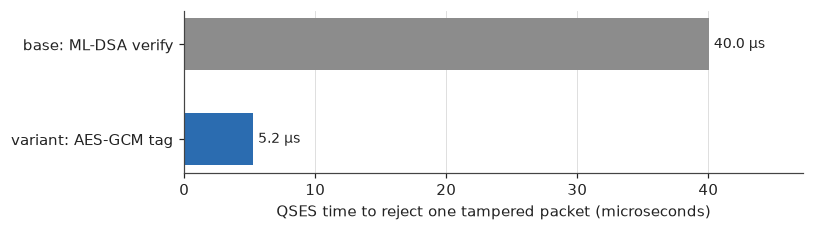

In [32]:
fresh_b = bytearray(client_b.create_signed_reading(TELEMETRY).to_bytes())
fresh_b[0] ^= 0x01                                       # flip one telemetry bit
forged_b = bytes(fresh_b)
fresh_s = bytearray(client_s.create_encrypted_reading(TELEMETRY).to_bytes())
fresh_s[SESSION_ID_SIZE + IV_SIZE] ^= 0x01               # flip one ciphertext bit
forged_s = bytes(fresh_s)

def reject_base(_):
    try:
        qses_b.process_and_forward(forged_b)
    except ProtocolError as e:
        return str(e)
    raise AssertionError("forged packet accepted by base QSES")

def reject_variant(_):
    try:
        qses_s.receive_from_sensor(forged_s)
    except ProtocolError as e:
        return str(e)
    raise AssertionError("forged packet accepted by variant QSES")

print("base rejects with   :", reject_base(None))
print("variant rejects with:", reject_variant(None))

t_rej_b, t_rej_s, _, _ = ab_loop(reject_base, [None] * (MICRO_N + 50), reject_variant, [None] * (MICRO_N + 50), warmup=50)
rej_b, rej_s = summarize(t_rej_b), summarize(t_rej_s)
rej_ratio = rej_b["mean"] / rej_s["mean"]
show_md(md_table(["QSES rejecting one tampered packet", "mean (µs)", "median (µs)", "p95 (µs)"], [
    ["base: reaches the ML-DSA verification", f"{rej_b['mean'] * 1e3:.1f}", f"{rej_b['median'] * 1e3:.1f}", f"{rej_b['p95'] * 1e3:.1f}"],
    ["variant: stops at the AES-GCM tag", f"{rej_s['mean'] * 1e3:.1f}", f"{rej_s['median'] * 1e3:.1f}", f"{rej_s['p95'] * 1e3:.1f}"],
]))
print(f"The base QSES spends {rej_ratio:.1f}x as long on a forged data packet.")
print("Caveat: the variant moves this exposure to the handshake. A forged HELLO also costs the QSES one ML-DSA verification.")
R["reject_cost"] = {"base": rej_b, "variant": rej_s, "ratio": rej_ratio}

fig, ax = plt.subplots(figsize=(7.5, 2.2))
vals = [rej_b["mean"] * 1e3, rej_s["mean"] * 1e3]
ax.barh([1, 0], vals, color=[BASE_C, SEC_C], height=0.55)
for y, v in zip([1, 0], vals):
    ax.text(v + max(vals) * 0.01, y, f"{v:.1f} µs", va="center", fontsize=9)
ax.set_yticks([1, 0])
ax.set_yticklabels(["base: ML-DSA verify", "variant: AES-GCM tag"])
ax.set_xlim(0, max(vals) * 1.18)
ax.set_xlabel("QSES time to reject one tampered packet (microseconds)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "fig5_reject_cost.png")
plt.show()

**Figure 5.** Cost to the QSES of rejecting a packet whose telemetry (base) or ciphertext (variant) was altered by one bit.

# Part C: what the variant does not do

## C1. The QSES still reads everything, and keeps the session key

The variant protects the radio link, not the data from the edge: the QSES needs the plaintext to verify the sensor's signature, in both variants. Because it also holds the session key for as long as the session exists, and nothing in the code ends a session, an attacker who later gets into QSES memory can open the sessions it recorded.

What the ephemeral ML-KEM key does give is protection against a later compromise of the sensor or of long-term signing keys: the sensor's ML-KEM secret key is deleted at the end of the handshake, and signing keys only authenticate, they never derive the session key.

In [33]:
# attacker: recorded sensor-link traffic + a copy of the QSES's session table
sid_cap = int.from_bytes(wire_s[0][:SESSION_ID_SIZE], "big")
stolen = qses_s.sessions[sid_cap]
recovered = 0
for w in cap_s:
    lp = SensorLinkPacket.from_bytes(w)
    plain = stolen.decrypt_detached(lp.iv, lp.ciphertext, lp.tag, lp.header())
    recovered += ClientPacket.from_bytes(plain).message.rstrip(b"\x00") == TELEMETRY
print(f"recorded packets opened with the key taken from QSES memory: {recovered} / {N_CAP}")
print(f"session keys the QSES still holds after the {HS_N + WARMUP} handshakes in A3: {len(hs_qses.sessions)}")
print(f"sensor still holds its ML-KEM secret key after the handshake: {client_s._kem is not None}")
R["qses_compromise"] = {"recovered": int(recovered), "of": N_CAP, "sensor_kem_sk_kept": client_s._kem is not None}

recorded packets opened with the key taken from QSES memory: 200 / 200
session keys the QSES still holds after the 320 handshakes in A3: 320
sensor still holds its ML-KEM secret key after the handshake: False


## C2. Other things found in the implementation

- **No session end, expiry or rekeying.** `SecureQSESNode.sessions` and `_seen_n_i` only grow. The paper's Algorithm 4 has `T_rekey` and `N_max`; the variant has neither.
- **Session id collisions.** `accept_session` draws a random 32-bit id and stores `sessions[id] = ...` without checking, so a collision silently replaces another sensor's key. Because nothing is evicted, the relevant count is sessions ever created; the birthday bound reaches 50 % at roughly 77,000.
- **Handshake has no wire format.** Messages are Python tuples; the byte counts in A4 assume 4-byte integer fields.
- **Sensor id is visible in HELLO.** Only the link after the handshake hides it.
- **Hop 2 is not forward-secret against the server key.** The QSES encapsulates to the server's long-lived ML-KEM key, which `MedicalServerNode` creates once and never replaces. Whoever obtains that secret key can open every recorded QSES → server packet. The per-session key on the sensor link is, in this respect, stronger than the paper's own second hop.
- **Timings are host timings.** The paper's own discussion lists hardware measurements as future work; none of the numbers here transfer to a microcontroller.

# Summary

In [34]:
def pct(a, b):
    return f"{100 * a / b:.1f} %"

rows = [
    ["Sensor time per reading, mean (µs)", f"{stages['Sensor']['base']['mean'] * 1e3:.1f}",
     f"{stages['Sensor']['secure']['mean'] * 1e3:.1f}", f"{ci_us(stages['Sensor']['d_mean'])} (end to end)", "measured, A/B"],
    ["Sensor added work per reading (µs)", "0", f"{add_sensor_ms * 1e3:.2f}",
     f"{pct(add_sensor_ms, stages['Sensor']['base']['mean'])} of base", "measured directly"],
    ["QSES time per reading, mean (µs)", f"{stages['QSES']['base']['mean'] * 1e3:.1f}",
     f"{stages['QSES']['secure']['mean'] * 1e3:.1f}", f"{ci_us(stages['QSES']['d_mean'])} (end to end)", "measured, A/B"],
    ["QSES added work per reading (µs)", "0", f"{add_qses_ms * 1e3:.2f}",
     f"{pct(add_qses_ms, stages['QSES']['base']['mean'])} of base", "measured directly"],
    ["Server time per reading, mean (µs)", f"{stages['Server (A/A control)']['base']['mean'] * 1e3:.1f}",
     f"{stages['Server (A/A control)']['secure']['mean'] * 1e3:.1f}", f"{ci_us(stages['Server (A/A control)']['d_mean'])}", "A/A control"],
    ["Sensor link bytes per reading", f"{CLIENT_PACKET_SIZE:,}", f"{LINK_PACKET_SIZE:,}",
     f"+{extra_per_reading} ({pct(extra_per_reading, CLIENT_PACKET_SIZE)})", "from the code"],
    ["QSES to server bytes per reading", f"{EDGE_PACKET_SIZE:,}", f"{EDGE_PACKET_SIZE:,}", "0", "from the code"],
    ["Handshake time at the sensor (µs)", "0", f"{hs_s_ms * 1e3:.0f}", f"{sensor_hs_in_readings:.1f} base readings", "measured"],
    ["Handshake time at the QSES (µs)", "0", f"{hs_q_ms * 1e3:.0f}", "", "measured"],
    ["Handshake bytes (sent / received by sensor)", "0", f"{hello_len:,} / {reply_len:,}", "", "computed, 4-byte ids"],
    ["Extra key storage on sensor (bytes)", "0", f"{SZ['sig_pk']:,} kept + {transient:,} during handshake", "", "from liboqs sizes"],
    ["QSES time to reject a tampered packet (µs)", f"{rej_b['mean'] * 1e3:.1f}", f"{rej_s['mean'] * 1e3:.1f}", f"{rej_ratio:.1f}x cheaper", "measured"],
    ["QSES state per session (bytes)", "0", f"about {per_session_bytes:,.0f}", "never freed", "measured"],
    ["Telemetry readable on the sensor link", f"{ob['readable']} / {N_CAP}", f"{os_['readable']} / {N_CAP}", "", "tested in B1"],
    ["Sensor authenticates the edge", "no", "yes", "", "tested in B2"],
]
show_md(md_table(["metric", "base", "variant", "difference", "how obtained"], rows))

| metric | base | variant | difference | how obtained |
|---|---|---|---|---|
| Sensor time per reading, mean (µs) | 82.1 | 87.8 | +5.6 [+2.2, +9.0] (end to end) | measured, A/B |
| Sensor added work per reading (µs) | 0 | 6.37 | 7.7 % of base | measured directly |
| QSES time per reading, mean (µs) | 148.3 | 154.1 | +5.8 [+2.2, +9.5] (end to end) | measured, A/B |
| QSES added work per reading (µs) | 0 | 3.61 | 2.4 % of base | measured directly |
| Server time per reading, mean (µs) | 154.9 | 156.6 | +1.7 [-45.4, +47.9] | A/A control |
| Sensor link bytes per reading | 2,584 | 2,616 | +32 (1.2 %) | from the code |
| QSES to server bytes per reading | 5,832 | 5,832 | 0 | from the code |
| Handshake time at the sensor (µs) | 0 | 185 | 2.2 base readings | measured |
| Handshake time at the QSES (µs) | 0 | 168 |  | measured |
| Handshake bytes (sent / received by sensor) | 0 | 3,240 / 3,208 |  | computed, 4-byte ids |
| Extra key storage on sensor (bytes) | 0 | 1,312 kept + 3,264 during handshake |  | from liboqs sizes |
| QSES time to reject a tampered packet (µs) | 40.0 | 5.2 | 7.6x cheaper | measured |
| QSES state per session (bytes) | 0 | about 299 | never freed | measured |
| Telemetry readable on the sensor link | 200 / 200 | 0 / 200 |  | tested in B1 |
| Sensor authenticates the edge | no | yes |  | tested in B2 |

In [35]:
s_pct = 100 * add_sensor_ms / stages["Sensor"]["base"]["mean"]
q_pct = 100 * add_qses_ms / stages["QSES"]["base"]["mean"]

def verdict(key):
    lo, hi = stages[key]["d_mean"][1], stages[key]["d_mean"][2]
    return "includes zero" if lo <= 0 <= hi else "excludes zero"

show_md(f"""
**Cost per reading.** The variant adds about {add_sensor_ms * 1e3:.1f} µs of work at the sensor ({s_pct:.1f} % of one base reading) and {add_qses_ms * 1e3:.1f} µs at the QSES ({q_pct:.1f} %), plus {extra_per_reading} bytes on the sensor link ({100 * extra_per_reading / CLIENT_PACKET_SIZE:.1f} %). The end-to-end A/B intervals for the sensor ({ci_us(stages['Sensor']['d_mean'])} µs, {verdict('Sensor')}) and the QSES ({ci_us(stages['QSES']['d_mean'])} µs, {verdict('QSES')}) are wider than the direct measurements because signing time is noisy; the A/A control interval is {ci_us(aa)} µs.

**Cost per session.** One handshake takes the sensor {hs_s_ms * 1e3:.0f} µs, equal to {sensor_hs_in_readings:.1f} base readings, and the QSES {hs_q_ms * 1e3:.0f} µs. The sensor sends {hello_len:,} bytes and receives {reply_len:,}. The handshake is the larger share of the sensor's extra time until a session reaches about {n_half_sensor:.0f} readings ({duration(n_half_sensor * SAMPLE_INTERVAL_S)} at one reading per {SAMPLE_INTERVAL_S} s), and of the extra bytes until about {n_half_bytes:.0f} readings.

**What the sensor gives up.** The paper's sensor only signs. The variant's sensor also runs ML-KEM key generation and decapsulation, one extra signature and one extra signature check per session, and keeps {SZ['sig_pk']:,} more bytes of key material permanently and {transient:,} more during the handshake.

**What it buys.** A passive listener on the sensor link decodes {os_['readable']} of {N_CAP} readings in the variant against {ob['readable']} of {N_CAP} in the base. The sensor refuses a handshake with an edge that lacks the QSES signing key. The QSES rejects tampered sensor packets at {rej_ratio:.1f}x lower cost.

**What it does not buy.** The QSES still reads every reading, and it keeps session keys with no expiry, so a compromised QSES exposes the sessions it recorded ({recovered} of {N_CAP} recovered in C1). Forward secrecy applies to later compromise of the sensor or of long-term signing keys.
""")


**Cost per reading.** The variant adds about 6.4 µs of work at the sensor (7.7 % of one base reading) and 3.6 µs at the QSES (2.4 %), plus 32 bytes on the sensor link (1.2 %). The end-to-end A/B intervals for the sensor (+5.6 [+2.2, +9.0] µs, excludes zero) and the QSES (+5.8 [+2.2, +9.5] µs, excludes zero) are wider than the direct measurements because signing time is noisy; the A/A control interval is +1.7 [-45.4, +47.9] µs.

**Cost per session.** One handshake takes the sensor 185 µs, equal to 2.2 base readings, and the QSES 168 µs. The sensor sends 3,240 bytes and receives 3,208. The handshake is the larger share of the sensor's extra time until a session reaches about 29 readings (14 min at one reading per 30 s), and of the extra bytes until about 202 readings.

**What the sensor gives up.** The paper's sensor only signs. The variant's sensor also runs ML-KEM key generation and decapsulation, one extra signature and one extra signature check per session, and keeps 1,312 more bytes of key material permanently and 3,264 more during the handshake.

**What it buys.** A passive listener on the sensor link decodes 0 of 200 readings in the variant against 200 of 200 in the base. The sensor refuses a handshake with an edge that lacks the QSES signing key. The QSES rejects tampered sensor packets at 7.6x lower cost.

**What it does not buy.** The QSES still reads every reading, and it keeps session keys with no expiry, so a compromised QSES exposes the sessions it recorded (200 of 200 recovered in C1). Forward secrecy applies to later compromise of the sensor or of long-term signing keys.


In [36]:
R["summary_rows"] = rows
with open(RESULTS_PATH, "w") as f:
    json.dump(R, f, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("saved", RESULTS_PATH)
if SAVE_FIGS:
    print("figures in", FIG_DIR)

for obj in (client_b, client_s, qses_b, qses_s, server_b, server_s, hs_client, hs_qses, hs_server,
            dev_signer, qses_signer, kem_pair):
    try:
        obj.close()
    except Exception:
        pass

saved /Users/prashant/pq-iomt-framework/comparison/comparison_results.json
figures in /Users/prashant/pq-iomt-framework/comparison/figures
